# Add Images to a dataset and re-trigger a training job

***
This notebook provides a walkthrough of [Amazon Rekognition Custom Labels API](https://docs.aws.amazon.com/rekognition/latest/customlabels-dg/custom-labels-api-reference.html) to add images to an existing dataset within a project (the project created as part of the [CustomObjectdetectionUsingRekognitionCustomLabelsAPI](custom-object-detection-using-rekognition-custom-labels-api.ipynb) notebook) and retrigger a training job.
<br>Before running this notebook, make sure to complete the steps in the [CustomObjectdetectionUsingRekognitionCustomLabelsAPI](custom-object-detection-using-rekognition-custom-labels-api.ipynb) notebook.
***

***
<b>Setup</b>
<br>To continue with this notebook, please make sure you have completed the steps in the [CustomObjectdetectionUsingRekognitionCustomLabelsAPI](custom-object-detection-using-rekognition-custom-labels-api.ipynb) notebook which is available in the same directory
***

In [ ]:
## Upgrade boto3 and botocore
!pip install botocore --upgrade
!pip install boto3 --upgrade

### Initialize Notebook

In [ ]:
import json
import xml.etree.ElementTree as ET
from datetime import datetime
from os import listdir, makedirs
from os.path import isfile, join
import shutil
import numpy as np
import base64

import boto3
from IPython.display import HTML, display, Image as IImage
from PIL import Image, ImageDraw, ImageFont
import time
import os

from IPython.display import JSON

In [ ]:
# Curent AWS Region. Use this to choose corresponding S3 bucket with sample content

mySession = boto3.session.Session()
awsRegion = mySession.region_name
print ("AWS Region : " + awsRegion)

In [ ]:
# Init clients
rekognition = boto3.client('rekognition')
s3 = boto3.client('s3')

***
Activities
***
In this notebook, we will extend the training and test dataset by adding two more classes (types) of dog breeds to the existing project's training and test dataset. Also re-trigger an Amazon Rekognition Custom Label training job to update the model to detect the new classes of dog breeds.
1. Prepare the datasets and generating manifest file.
2. Retrive existing Project details.
3. Import the Datasets into the existing Project's training and test datasets.
4. Re-trigger a training job to update the model to detect the new Dog breeds.
5. Retrieve the Model Metrics.
6. Start the Inference endpoint.
7. Run predictions on the holdout dataset.
8. Stop the Inference endpoint.
***

In [ ]:
## Please replace the <rek_cl_default_bucket_name> with the value of the Amazon S3 bucket name captured in the CustomObjectdetectionUsingRekognitionCustomLabelsAPI notebook
rek_cl_default_bucket = "<rek_cl_default_bucket_name>"


### Prepare the datasets and generating manifest file
***
The original dataset contains 120 classes and 20,000+ images. 
<br>This is possible to train with custom labels, but it will take many hours. 
<br>For this scenario, we will add 2 new classes to the existing training and test datasets. Along with providing easier to read names. 
<br>We will also demonstrate the generation of a Amazon Sageamker Groundtruth manifest file from the XML format annotation available with the public dataset. 
<br>We will include the images for the Saluki Dog breed in the existing training dataset.
<br>We will split the new class into an approximate 80-20 ratio. 80% percent of the dataset for the new classes is added to the existing training dataset and the remaining 20% is added to the existing test dataset.
***

In [ ]:
## Function to convert a list of stanford dog dataset annotation to generate a single Amazon Sagemaker groundtruth manifest file.
def generate_manifest_file (stanford_dog_dataset_annotation, final_manifest_file_path, dataset_type):
    final_file=[]
    class_dict={}
    for filename in stanford_dog_dataset_annotation:
        file_pth = filename.replace('/images/Images/','/annotation/Annotation/').replace('.jpg','')
        # print(file_pth)
        file = open(file_pth, mode = 'r' )
        annt = file.read()
        # print (annt)
        singl_file = {}
        # print ("\n")
        root = ET.fromstring(annt)
        img_size = {}
        img_nm = None
        for child in root:
            if (child.tag == 'filename'):
                # print (child.text)
                img_nm = child.text

            if (child.tag == 'size'):
                for elem in child.iter():
                    if (elem.tag == 'width'):
                        # print (elem.text)
                        img_size["width"]=int(elem.text)
                    if (elem.tag == 'height'):
                        # print (elem.text)
                        img_size["height"] = int(elem.text)
                    if (elem.tag == 'depth'):
                        # print (elem.text)
                        img_size["depth"] = int(elem.text)
        # print (json.dumps(singl_file))
        annotations = []
        objects = []
        class_map = {}
        objcts = root.findall('object')
        # print (len(objcts))
        for objct in objcts:
            annotation = {}
            confidence = {}
            class_nm = None
            class_id = None
            for elem in objct.iter():
                if (elem.tag == 'name'):
                    # print(elem.text)
                    class_nm = elem.text
                    class_id = class_dict.get(class_nm, None)
                    if class_id == None:
                        if len(class_dict) == 0:
                            class_id = 0
                        else:
                            all_values = class_dict.values()
                            max_value = max(all_values)
                            class_id = int(max_value) + 1
                        class_dict[class_nm] = class_id

                if (elem.tag == 'bndbox'):
                    xmin = ymin = xmax = ymax = 0
                    for subelem in elem.iter():
                        if (subelem.tag == 'xmin'):
                            # print(subelem.text)
                            xmin = int(subelem.text)
                        if (subelem.tag == 'ymin'):
                            # print(subelem.text)
                            ymin = int(subelem.text)
                        if (subelem.tag == 'xmax'):
                            # print(subelem.text)
                            xmax = int(subelem.text)
                        if (subelem.tag == 'ymax'):
                            # print(subelem.text)
                            ymax = int(subelem.text)

                    annotation["class_id"] = class_id
                    annotation["top"] = ymin
                    annotation["left"] = xmin
                    annotation["width"] = xmax - xmin
                    annotation["height"] = ymax - ymin
                    annotations.append(annotation)

                    confidence["confidence"] = 1
                    objects.append(confidence)

                    class_map[class_id] = class_nm
        bbx = {
            "image_size" : [img_size],
            "annotations" : annotations
        }

        bbx_mtdata = {
            "objects" : objects,
            "class-map" : class_map,
            "type": "groundtruth/object-detection",
            "human-annotated": "yes",
            "creation-date": datetime.today().strftime('%Y-%m-%dT%H:%m:%S'), 
            "job-name": "testjob"
        }


        singl_file = {
            "source-ref" : f's3://{rek_cl_default_bucket}/stanford_dog_dataset/{dataset_type}/{img_nm}.jpg',
            "bounding-box" : bbx,
            "bounding-box-metadata" : bbx_mtdata

        }

        # print (json.dumps(singl_file))
        imglbl = json.dumps(singl_file)
        final_file.append(imglbl + " \n")
        file.close()
    
    file1 = open(final_manifest_file_path, "w")
    file1.writelines(final_file)
    file1.close()

In [ ]:
classes_to_be_trained = [
    ## This is the dog breed which was missing in the previous notebook or classified as a different dog breed. Now we are adding the Saluki dog breed images to the training dataset to improve the model
    "n02091831-Saluki"
]

holdoutset_list = {
    ## This is the same image which was added to holdout dataset in the previous email
    "n02091831-Saluki" : "./stanford_dog_dataset/images/Images/n02091831-Saluki/n02091831_3909.jpg"
}

In [ ]:
training_dataset_list = []
test_dataset_list = []

## Generating new dataset for training and test
for class_nm in classes_to_be_trained:
    new_path_train = f'./stanford_dog_dataset/update_train_dataset/'
    makedirs(new_path_train, exist_ok=True)
    new_path_test = f'./stanford_dog_dataset/update_test_dataset/'
    makedirs(new_path_test, exist_ok=True)
    
    existing_path = f'./stanford_dog_dataset/images/Images/{class_nm}'
    onlyfiles = [join(existing_path, f) for f in listdir(existing_path) if isfile(join(existing_path, f))]
    # remove the image from the list which is kept as part of the holdout dataset.
    onlyfiles.remove(holdoutset_list[class_nm])
    
    indices_for_splittin = [int(len(onlyfiles) * 0.8)]
    update_train_list, update_test_list = np.split(onlyfiles, indices_for_splittin)
    
    for train_file_pth in update_train_list:
        training_dataset_list.append(train_file_pth)
        dest_train_dataset_image_path = f'{new_path_train}/{train_file_pth.split("/")[-1]}'
        shutil.copy(train_file_pth, dest_train_dataset_image_path)
        
    for test_file_pth in update_test_list:
        test_dataset_list.append(test_file_pth)
        dest_test_dataset_image_path = f'{new_path_test}/{test_file_pth.split("/")[-1]}'
        shutil.copy(test_file_pth, dest_test_dataset_image_path)
    

## Generating updated train dataset manifest file
generate_manifest_file (training_dataset_list, './stanford_dog_dataset/update_train_dataset/train_dataset.manifest', 'update_train_dataset')

## Generating updated train dataset manifest file
generate_manifest_file (test_dataset_list, './stanford_dog_dataset/update_test_dataset/test_dataset.manifest', 'update_test_dataset')
    

## Copy the train and test dataset to the Amazon Rekognition Custom Label default S3 bucket
!aws s3 cp ./stanford_dog_dataset/update_train_dataset/ s3://$rek_cl_default_bucket/stanford_dog_dataset/update_train_dataset/ --recursive --quiet
!aws s3 cp ./stanford_dog_dataset/update_test_dataset/ s3://$rek_cl_default_bucket/stanford_dog_dataset/update_test_dataset/ --recursive --quiet



### Retrieve an existing Rekognition Custom Labels Project details
***
Here we will use the [describe_projects](https://boto3.amazonaws.com/v1/documentation/api/latest/reference/services/rekognition.html#Rekognition.Client.describe_projects) API to retrieve the details of an existing project which was created in the previous notebook.
***

In [ ]:
project_nm = "stanford_dogs_dataset_project"
cl_project = rekognition.describe_projects(
    ProjectNames=['stanford_dogs_dataset_project']
)
JSON(cl_project)

### Import the Datasets into the existing Project's training and test datasets.
***
Here we will use the [update_dataset_entries](https://boto3.amazonaws.com/v1/documentation/api/latest/reference/services/rekognition.html#Rekognition.Client.update_dataset_entries) API to add the new images to the existing training and test datasets of an existing project.
***

In [ ]:
## We will use the train_dataset.manifest and test_dataset.manifest file which was created earlier, to update the existing training and test datasets.

project_arn = cl_project['ProjectDescriptions'][0]['ProjectArn']
training_dataset_arn = ""
test_dataset_arn = ""
for ds in cl_project['ProjectDescriptions'][0]['Datasets']:
    if ds['DatasetType'] == 'TRAIN':
        training_dataset_arn = ds['DatasetArn']
    else:
        test_dataset_arn = ds['DatasetArn']
        

s3_connection = boto3.resource('s3')
##Update training datasets
s3_object = s3_connection.Object(rek_cl_default_bucket,'stanford_dog_dataset/update_train_dataset/train_dataset.manifest')
s3_response = s3_object.get()
content = s3_response['Body'].read()

cl_update_dataset_train = rekognition.update_dataset_entries(
                                DatasetArn=training_dataset_arn,
                                Changes={
                                    'GroundTruth': content
                                }
                            )
JSON(cl_update_dataset_train)

In [ ]:
##Update test datasets
s3_object = s3_connection.Object(rek_cl_default_bucket,'stanford_dog_dataset/update_test_dataset/test_dataset.manifest')
s3_response = s3_object.get()
content = s3_response['Body'].read()

cl_update_dataset_test = rekognition.update_dataset_entries(
                                DatasetArn=test_dataset_arn,
                                Changes={
                                    'GroundTruth': content
                                }
                            )
JSON(cl_update_dataset_test)

In [ ]:
## Wait for the training and test datasets to be updated
chk_status = True
starttime = time.time()
while (chk_status):
    ## wait for 2 minute. To check status every 2 minutes
    time.sleep (120)
    dataset_status_train = rekognition.describe_dataset(
                                DatasetArn=training_dataset_arn
                            )
    dataset_status_test = rekognition.describe_dataset(
                                DatasetArn=test_dataset_arn
                            )
    if ( (dataset_status_train['DatasetDescription']['Status'] != 'UPDATE_IN_PROGRESS') and (dataset_status_test['DatasetDescription']['Status'] != 'UPDATE_IN_PROGRESS') ):
        chk_status = False
    ## Continue to check for status for 1 hour
    if ((time.time() - starttime) > 3600):
        chk_status = False
        # Raise an exception if needed
        
JSON(dataset_status_train)

In [ ]:
JSON(dataset_status_test)

### The datasets can be verified from the AWS Console if needed
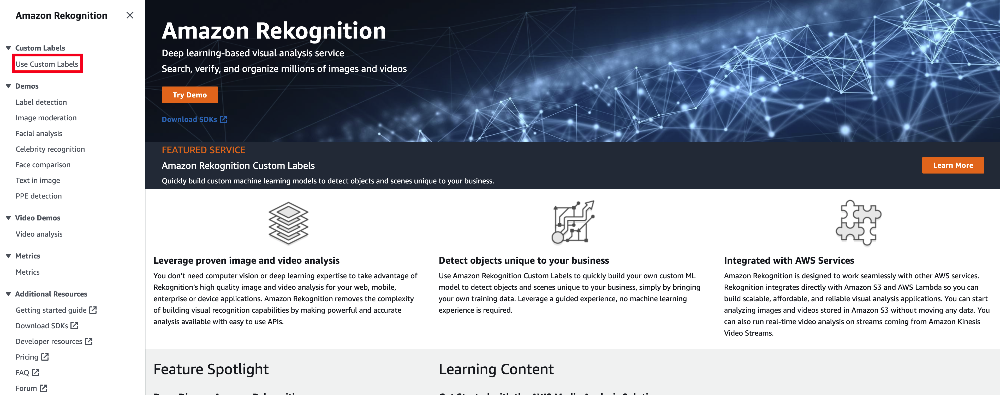
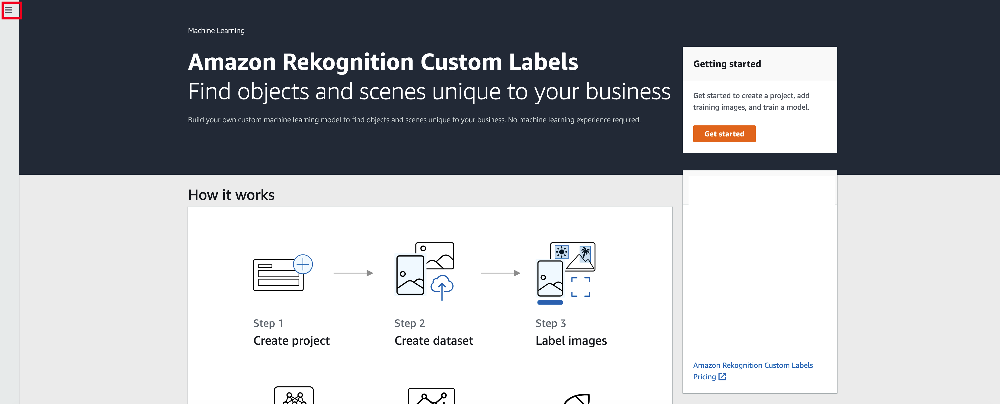
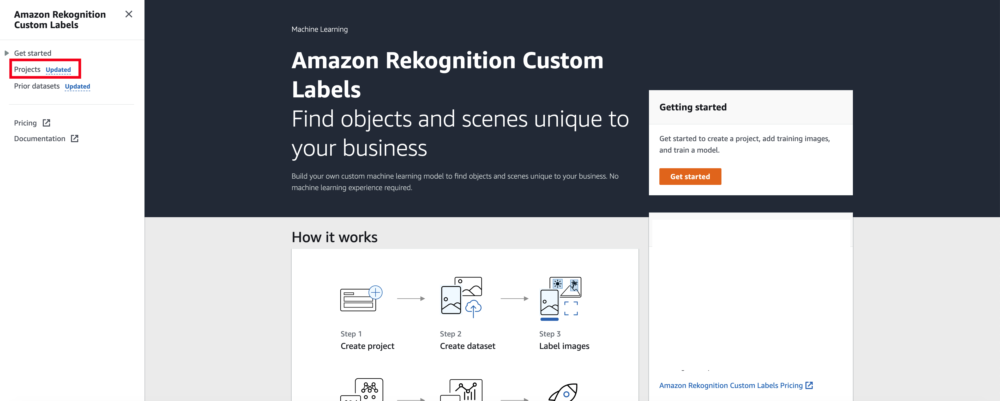
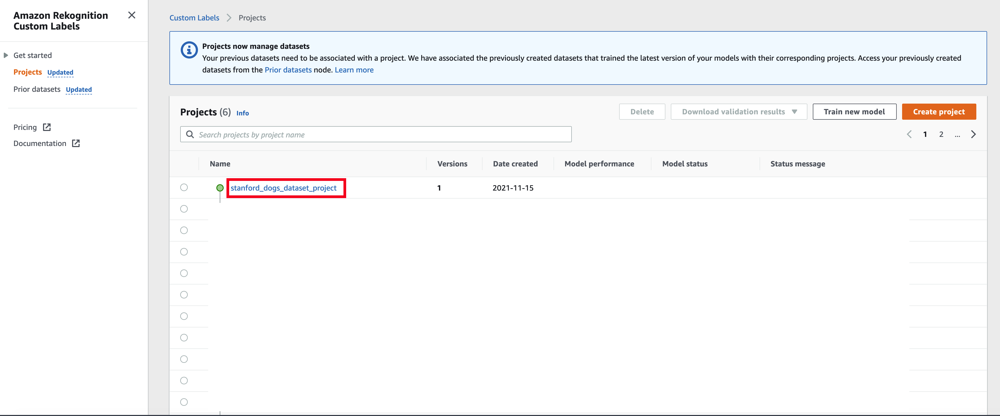
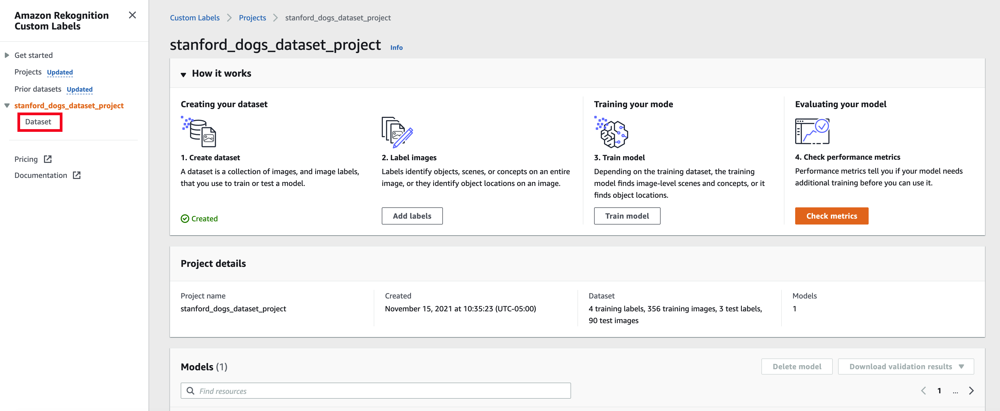
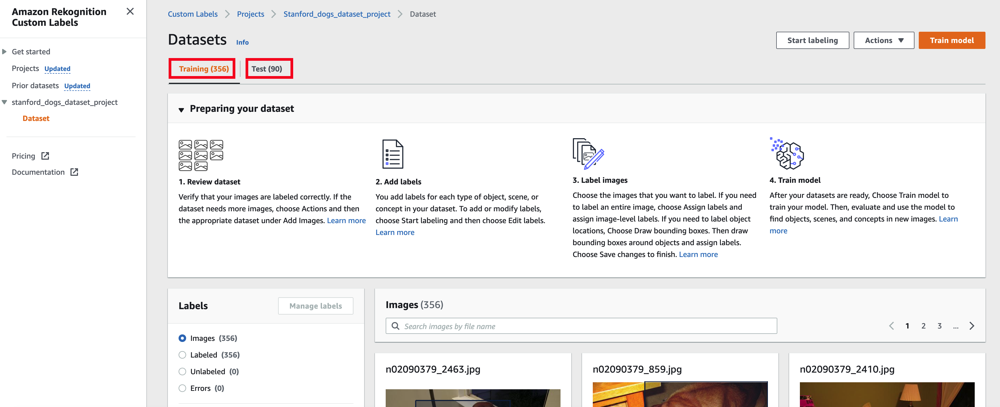
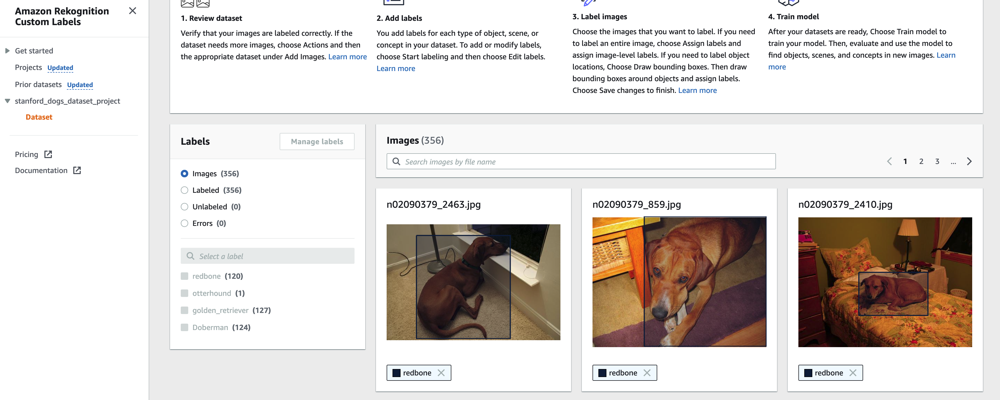

### Train a Custom Model to detect two new Dog breeds
***
Here we will use the [create_project_version](https://boto3.amazonaws.com/v1/documentation/api/latest/reference/services/rekognition.html#Rekognition.Client.create_project_version) API to re-train the model.
***

In [ ]:
## Start Training the model
model_version_name = f'model_v{str(int(time.time()))}'
cl_train_model = rekognition.create_project_version(
                        ProjectArn=project_arn,
                        VersionName=model_version_name,
                        OutputConfig={
                            'S3Bucket': rek_cl_default_bucket,
                            'S3KeyPrefix': 'stanford_dog_dataset/model_train_updated'
                        }
                    )
JSON(cl_train_model)

In [ ]:
## Wait for the training to finish. This may take 2 to 4 hours
chk_status = True
starttime = time.time()
while (chk_status):
    ## wait for 30 minute. To check status every 30 minutes
    time.sleep (1800)
    model_traing_status = rekognition.describe_project_versions(
                                ProjectArn=project_arn,
                                VersionNames=[
                                               model_version_name
                                            ]
        
                            )
    if ( (model_traing_status['ProjectVersionDescriptions'][0]['Status'] != 'TRAINING_IN_PROGRESS') ):
        chk_status = False
    ## Continue to check for status for 10 hour
    if ((time.time() - starttime) > 36000):
        chk_status = False
        # Raise an exception if needed
        
JSON(model_traing_status)


### Retrieve the Model Metrics
***
Here we will use the [describe_project_versions](https://boto3.amazonaws.com/v1/documentation/api/latest/reference/services/rekognition.html#Rekognition.Client.describe_project_versions) API to retrive the trained model metrics.
<br>To understand mroe about the metrics please refer [Metrics for evaluating your model](https://docs.aws.amazon.com/rekognition/latest/customlabels-dg/im-metrics-use.html)
<br> To programatically access more granular results related to the model. Please refer [Accessing Amazon Rekognition Custom Labels training results](https://docs.aws.amazon.com/rekognition/latest/customlabels-dg/im-metrics-api.html)
***

In [ ]:
model_metrics = rekognition.describe_project_versions(
                                ProjectArn=project_arn,
                                VersionNames=[
                                               model_version_name
                                            ]
        
                            )
# model_metrics

print ("F1 Score " + str(model_metrics['ProjectVersionDescriptions'][0]['EvaluationResult']['F1Score']))

s3 = boto3.resource('s3')
content_object = s3.Object(model_metrics['ProjectVersionDescriptions'][0]['EvaluationResult']['Summary']['S3Object']['Bucket'], 
                          model_metrics['ProjectVersionDescriptions'][0]['EvaluationResult']['Summary']['S3Object']['Name'] )
file_content = content_object.get()['Body'].read().decode('utf-8')
json_content = json.loads(file_content)

JSON(json_content)

### The model results and metrics can also be viewed from the AWS Console
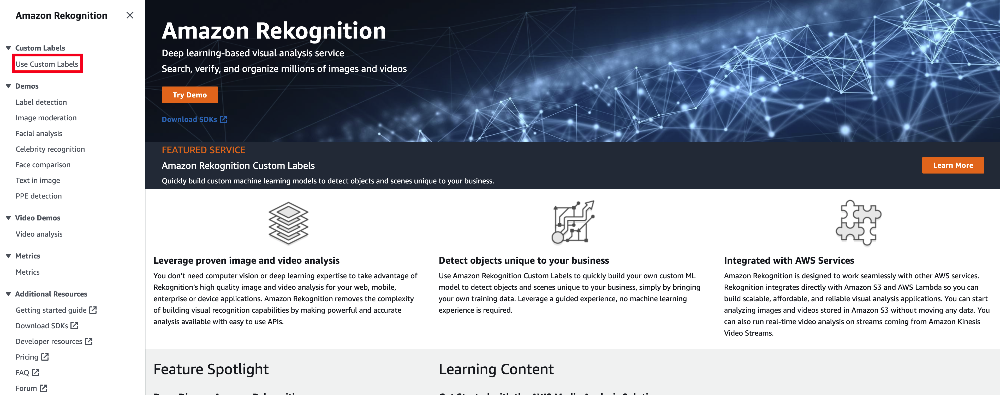
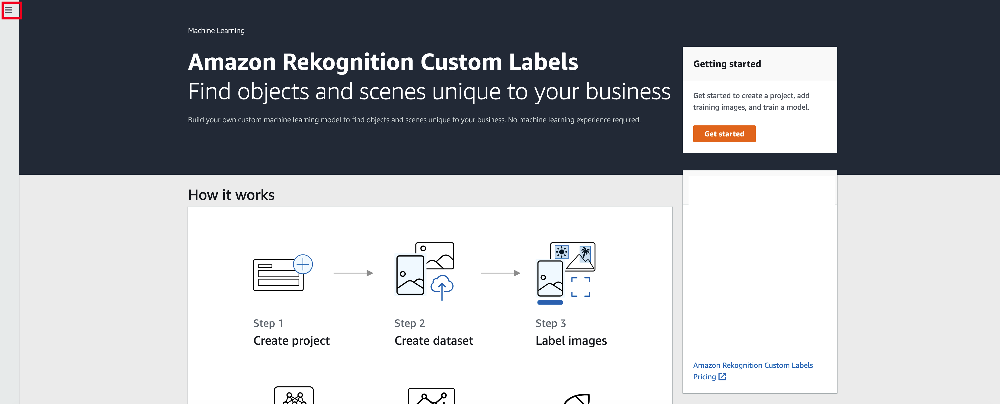
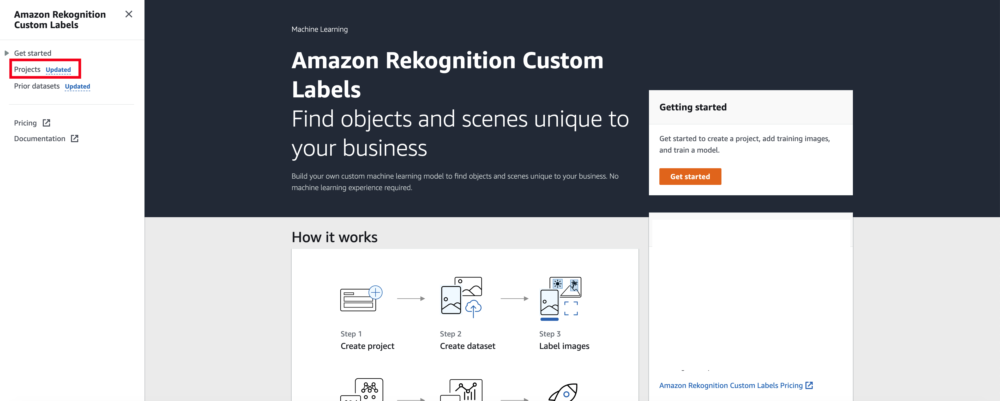
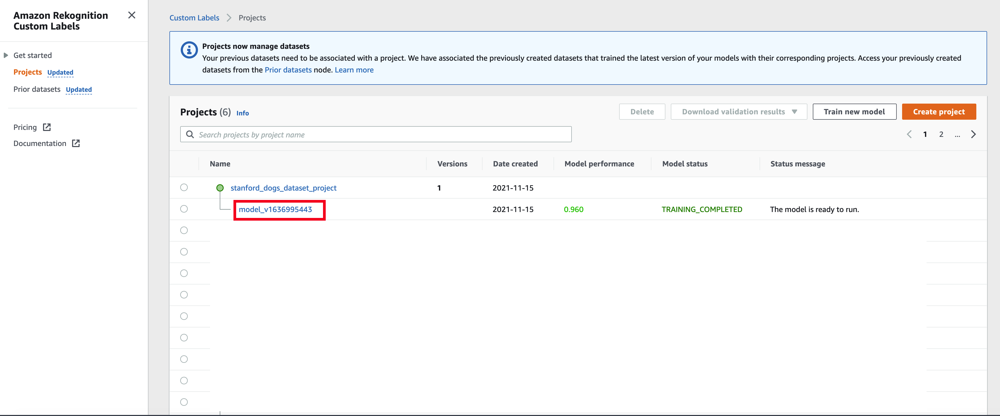
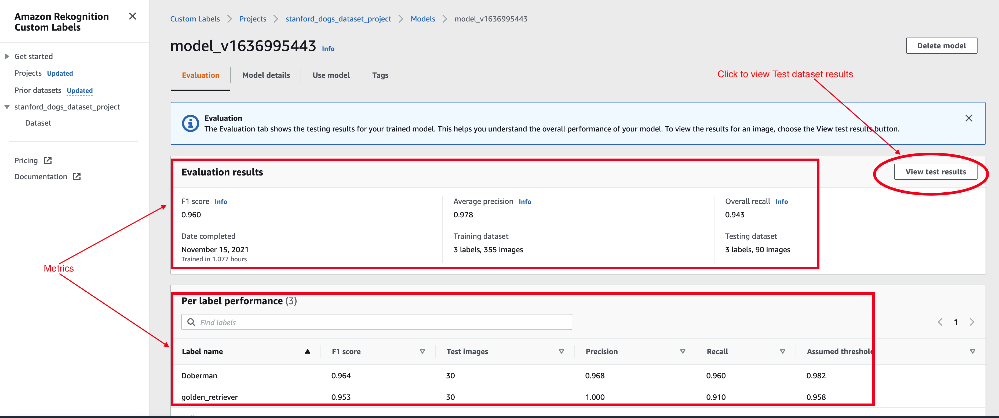
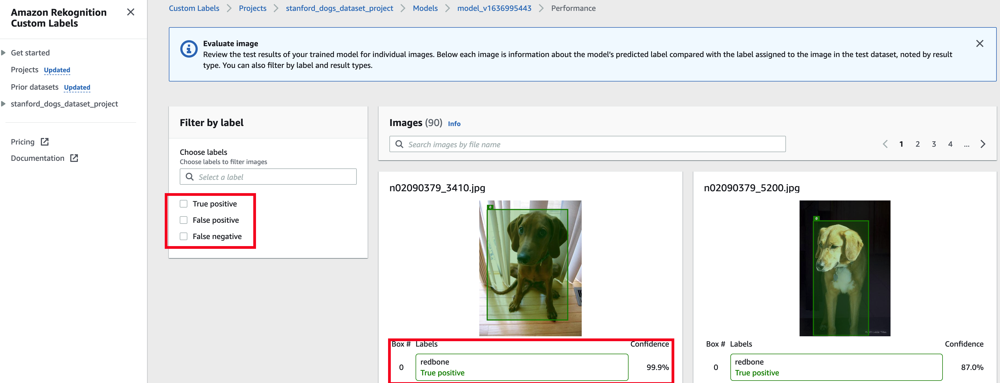

### Start the trained model
***
Here we will use the [start_project_version](https://boto3.amazonaws.com/v1/documentation/api/latest/reference/services/rekognition.html#Rekognition.Client.start_project_version) API to start the trained model.
***

In [ ]:
start_model = rekognition.start_project_version(
                        ProjectVersionArn=model_metrics['ProjectVersionDescriptions'][0]['ProjectVersionArn'],
                        MinInferenceUnits=1
                    )
JSON (start_model)

In [ ]:
## Wait for the model to start
chk_status = True
starttime = time.time()
while (chk_status):
    ## wait for 5 minute. To check status every 5 minutes
    time.sleep (300)
    model_start_status = rekognition.describe_project_versions(
                                ProjectArn=project_arn,
                                VersionNames=[
                                               model_version_name
                                            ]
        
                            )
    if ( (model_start_status['ProjectVersionDescriptions'][0]['Status'] != 'STARTING') ):
        chk_status = False
    ## Continue to check for status for 1 hour
    if ((time.time() - starttime) > 3600):
        chk_status = False
        # Raise an exception if needed
        
JSON(model_start_status)


### Run tests on the holdout images
***
Here we will use the [detect_custom_labels](https://boto3.amazonaws.com/v1/documentation/api/latest/reference/services/rekognition.html#Rekognition.Client.detect_custom_labels) API to retrieve the dog breeds. These images were kept aside and was not included into the training or test datasets.
***

In [ ]:
#Copyright 2021 Amazon.com, Inc. or its affiliates. All Rights Reserved.
#PDX-License-Identifier: MIT-0 (For details, see https://github.com/awsdocs/amazon-rekognition-custom-labels-developer-guide/blob/master/LICENSE-SAMPLECODE.)

import boto3
import io
import logging
from PIL import Image, ImageDraw, ImageFont
from IPython.display import HTML, display


from botocore.exceptions import ClientError

logger = logging.getLogger(__name__)

def analyze_local_image(rek_client, model, photo, min_confidence):
    """
    Analyzes an image stored as a local file.
    :param rek_client: The Amazon Rekognition Boto3 client.
    :param s3_connection: The Amazon S3 Boto3 S3 connection object.
    :param model: The ARN of the Amazon Rekognition Custom Labels model that you want to use.
    :param photo: The name and file path of the photo that you want to analyze.
    :param min_confidence: The desired threshold/confidence for the call.
    """

    try:
        logger.info ("Analyzing local file: %s", photo)
        image=Image.open(photo) 
        image_type=Image.MIME[image.format]

        if (image_type == "image/jpeg" or image_type== "image/png") == False:
            logger.error("Invalid image type for %s", photo)
            raise ValueError(
                f"Invalid file format. Supply a jpeg or png format file: {photo}"
            )
            
        # get images bytes for call to detect_anomalies
        image_bytes = io.BytesIO()
        image.save(image_bytes, format=image.format)
        image_bytes = image_bytes.getvalue()

        response = rek_client.detect_custom_labels(Image={'Bytes': image_bytes},
            MinConfidence=min_confidence,
            ProjectVersionArn=model)

        show_image (image, response)
        return len(response['CustomLabels'])

    except ClientError as err:
        logger.error(format(err))
        raise
    

def analyze_s3_image(rek_client,s3_connection, model,bucket,photo, min_confidence):
    """
    Analyzes an image stored in the specified S3 bucket.
    :param rek_client: The Amazon Rekognition Boto3 client.
    :param s3_connection: The Amazon S3 Boto3 S3 connection object.
    :param model: The ARN of the Amazon Rekognition Custom Labels model that you want to use.
    :param bucket: The name of the S3 bucket that contains the image that you want to analyze.
    :param photo: The name of the photo that you want to analyze.
    :param min_confidence: The desired threshold/confidence for the call.
    """

    try:
        #Get image from S3 bucket.
        
        logger.info("analyzing bucket: %s image: %s", bucket, photo)
        s3_object = s3_connection.Object(bucket,photo)
        s3_response = s3_object.get()
        

        stream = io.BytesIO(s3_response['Body'].read())
        image=Image.open(stream)

        image_type=Image.MIME[image.format]

        if (image_type == "image/jpeg" or image_type== "image/png") == False:
            logger.error("Invalid image type for %s", photo)
            raise ValueError(
                f"Invalid file format. Supply a jpeg or png format file: {photo}")
                

        img_width, img_height = image.size  
        draw = ImageDraw.Draw(image)  
        
        #Call DetectCustomLabels 
        response = rek_client.detect_custom_labels(Image={'S3Object': {'Bucket': bucket, 'Name': photo}},
            MinConfidence=min_confidence,
            ProjectVersionArn=model)

        show_image (image, response)
        return len(response['CustomLabels'])

    except ClientError as err:
        logger.error(format(err))
        raise

def show_image(image, response):
    """
    Displays the analyzed image and overlays analysis results
    :param image: The analyzed image
    :param response: the response from DetectCustomLabels
    """
    try: 
        font_size=10
        line_width=5

        img_width, img_height = image.size  
        draw = ImageDraw.Draw(image)  
                
        # calculate and display bounding boxes for each detected custom label       
        image_level_label_height = 0
        
        for custom_label in response['CustomLabels']:
            confidence=int(round(custom_label['Confidence'],0))
            label_text=f"{custom_label['Name']}:{confidence}%"
#             font = ImageFont.load("arial.pil")
            fnt = ImageFont.truetype("/usr/share/fonts/dejavu/DejaVuSans.ttf", font_size)
            text_width, text_height = draw.textsize(label_text,fnt)

            logger.info(f"Label: {custom_label['Name']}") 
            logger.info(f"Confidence:  {confidence}%")

            # Draw bounding boxes, if present
            if 'Geometry' in custom_label:
                box = custom_label['Geometry']['BoundingBox']
                left = img_width * box['Left']
                top = img_height * box['Top']
                width = img_width * box['Width']
                height = img_height * box['Height']
                
                logger.info("Bounding box")
                logger.info("\tLeft: {0:.0f}".format(left))
                logger.info("\tTop: {0:.0f}".format(top))
                logger.info("\tLabel Width: {0:.0f}".format(width))
                logger.info("\tLabel Height: {0:.0f}".format(height))
                
                points = (
                    (left,top),
                    (left + width, top),
                    (left + width, top + height),
                    (left , top + height),
                    (left, top))
                #Draw bounding box and label text
                draw.line(points, fill="limegreen", width=line_width)
                draw.rectangle([(left + line_width , top+line_width), (left + text_width + line_width, top + line_width + text_height)],fill="black")
                draw.text((left + line_width ,top +line_width), label_text, fill="limegreen", font=fnt) 
            
            #draw image-level label text.
            else:
                draw.rectangle([(10 , image_level_label_height), (text_width + 10, image_level_label_height+text_height)],fill="black")
                draw.text((10,image_level_label_height), label_text, fill="limegreen", font=fnt)  

                image_level_label_height += text_height
            
#         image.show()
        display(image)

    except Exception as err:
        logger.error(format(err))
        raise
        

def analyze_rekcl_bb(bckt_nm, pics, modelarn, minconfdnce):

    try:
        logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")

        bucket=bckt_nm
        photos=pics
        model=modelarn
        min_confidence=minconfdnce
       

        rek_client=boto3.client('rekognition')
        
        s3_connection = boto3.resource('s3')
        for photo in photos:
            label_count=analyze_s3_image(rek_client,
                s3_connection,
                model,
                bucket,
                photo,
                min_confidence)
            
            
            
            

        """
        # Uncomment to analyze a local file. 
        # Change photo to the path and file name of a local file.
        label_count=analyze_local_image(rek_client,
            model,
            photo,
            min_confidence)
        
        """ 
        logger.info(f"Custom labels detected: {label_count}")

    except ClientError as err:
        print("A service client error occurred: " + format(err.response["Error"]["Message"]))
    except ValueError as err:
        print ("A value error occurred: " + format(err))




In [ ]:
## Test the model on the holdout dataset
bucket_nm=rek_cl_default_bucket
holdout_photos=[('stanford_dog_dataset/holdout/' + f) for f in listdir('./stanford_dog_dataset/holdout') if (isfile(join('./stanford_dog_dataset/holdout', f)) and ((f.split(".")[-1]) == 'jpg' ) )]
model_arn=model_metrics['ProjectVersionDescriptions'][0]['ProjectVersionArn']
min_confidence=80

analyze_rekcl_bb(bucket_nm, holdout_photos, model_arn, min_confidence)


### Stop the trained model
***
Here we will use the [stop_project_version](https://boto3.amazonaws.com/v1/documentation/api/latest/reference/services/rekognition.html#Rekognition.Client.stop_project_version) API to retrive the trained model metrics.
***

In [ ]:
stop_model = rekognition.stop_project_version(
                        ProjectVersionArn=model_metrics['ProjectVersionDescriptions'][0]['ProjectVersionArn']
                    )
JSON (stop_model)

In [ ]:
## Wait for the model to stop
chk_status = True
starttime = time.time()
while (chk_status):
    ## wait for 5 minute. To check status every 5 minutes
    time.sleep (300)
    model_stop_status = rekognition.describe_project_versions(
                                ProjectArn=project_arn,
                                VersionNames=[
                                               model_version_name
                                            ]
        
                            )
    if ( (model_stop_status['ProjectVersionDescriptions'][0]['Status'] != 'STOPPING') ):
        chk_status = False
    ## Continue to check for status for 1 hour
    if ((time.time() - starttime) > 3600):
        chk_status = False
        # Raise an exception if needed
        
JSON(model_stop_status)


You have successfully used Amazon Rekognition Custom Label APIs to add Saluki dog breed images to the training and test dataset to run a Rekognition Custom Label Re-training and Inference flow to detect dog breeds.
<br>You must noticed that the image Saluki.jpg is correctly classified.
<br>The apis can be leveraged to integrate with your current system or your existing ML/AI flows to re-train a model with updated datasets.


### Learn more about different Rekognition Custom Labels APIs
***
To learn more about the Rekognition Custom Labels APIs [Amazon Rekognition Custom Labels API reference](https://docs.aws.amazon.com/rekognition/latest/customlabels-dg/custom-labels-api-reference.html)
<br> To learn about how you can integrate [Amazon Augmented AI (Amazon A2I)](https://aws.amazon.com/blogs/machine-learning/using-amazon-rekognition-custom-labels-and-amazon-a2i-for-detecting-pizza-slices-and-augmenting-predictions/) to include a Human Verification Loop in your workflow. Please refer the blog post [Using Amazon Rekognition Custom Labels and Amazon A2I for detecting pizza slices and augmenting predictions](https://aws.amazon.com/blogs/machine-learning/using-amazon-rekognition-custom-labels-and-amazon-a2i-for-detecting-pizza-slices-and-augmenting-predictions/)
***

Stop the Amazon Sagemaker Notebook instance, if you created one to run the demonstration